<a href="https://colab.research.google.com/github/Lauralug0/GBC/blob/main/Laura_resume_matching_transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 **Resume and Job Description Matching
Applied Mathematics Concepts for Deep Learning**

Author: Laura Lugo Latorre  
Course: Applied Math Concepts for Deep Learning  
Approach: Fine-tuning a Transformer-based deep learning model  

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

**Objective**

The objective of this project is to train a deep learning model that predicts
whether a candidate will be selected or rejected for a job position based on
the relationship between a resume and a job description.

This problem is formulated as a binary classification task:
  

*   1: Selected
*   0: Rejected


   




**Models:**
- distilbert-base-uncased: fine-tuned for binary classification (select / reject)
- intfloat/e5-large-v2: used for dense embedding generation and semantic similarity

**Pipeline:**
- Load and clean dataset
- Stratified train/validation/test split
- Tokenization of (Resume, Job_Description) pairs
- Fine-tuning DistilBERT for binary classification
- Evaluation with accuracy, F1, ROC-AUC
- Threshold calibration using validation set
- Artifact and figure generation


# 1. Environment Setup


In [1]:
"""
Environment setup for Google Colab.

This section:
- Mounts Google Drive to access project files
- Sets the project working directory
- Installs and verifies required dependencies for the NLP pipeline

Note:
This code is intended to be executed in a Google Colab environment.
"""

# Mount Google Drive to access project files
from google.colab import drive
drive.mount("/content/drive")

# Define and move to project directory
PROJECT_DIR = "/content/drive/MyDrive/career-portal"
%cd $PROJECT_DIR


# Install required libraries
!pip install -q torch transformers datasets accelerate evaluate scikit-learn matplotlib seaborn
!pip install -qU "transformers>=4.40" "accelerate>=0.25" "datasets>=2.15" "evaluate>=0.4" "scikit-learn"

# Verify library versions for reproducibility
import transformers
import accelerate
import datasets
import evaluate
import torch

print("transformers:", transformers.__version__)
print("accelerate:", accelerate.__version__)
print("datasets:", datasets.__version__)
print("evaluate:", evaluate.__version__)
print("torch:", torch.__version__)


Mounted at /content/drive
/content/drive/.shortcut-targets-by-id/1vZ--GzeC1X5Ito3ABy99iPziieT--Mcr/career-portal
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 91.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 515.2/515.2 kB 52.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 77.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 16.6 MB/s eta 0:00:00
transformers: 5.1.0
accelerate: 1.12.0
datasets: 4.5.0
evaluate: 0.4.6
torch: 2.9.0+cu126


# 2. Imports

In [2]:
"""
Import required libraries for data processing, modeling,
evaluation, and visualization.
"""

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)

import evaluate



# 3 Dataset Loading

In [3]:
"""
Load the cleaned dataset and create binary labels
from the Decision column.
"""

# Load cleaned dataset
DATA_PATH = os.path.join(PROJECT_DIR, "data", "dataset_clean.csv")

df = pd.read_csv(DATA_PATH)
df = df.dropna(subset=["Resume","Job_Description","Decision"]).copy()
df["label"] = (df["Decision"].str.lower() == "select").astype(int)

print(df.shape)
df.head()

(10174, 6)


,Role,Resume,Decision,Reason_for_decision,Job_Description,label
0,E-commerce Specialist,Jason Jones\nE-commerce Specialist\nSummary:\n...,reject,Lacked leadership skills for a senior position.,Be part of a passionate team at the forefront ...,0
1,Game Developer,Ann Marshall\nSummary:\nHighly motivated and d...,select,Strong technical skills in AI and ML.,Help us build the next-generation products as ...,1
2,Human Resources Specialist,Patrick Mcclain\nHuman Resources Specialist\nP...,reject,Insufficient system design expertise for senio...,We need a Human Resources Specialist to enhanc...,0
3,E-commerce Specialist,Patricia Gray\nProfessional Summary:\nResults-...,select,Impressive leadership and communication abilit...,Be part of a passionate team at the forefront ...,1
4,E-commerce Specialist,Amanda Gross\nProfessional Summary:\nResults-d...,reject,Lacked leadership skills for a senior position.,We are looking for an experienced E-commerce S...,0


#4. Train
We split the dataset into **training, validation, and test sets** while preserving the label distribution (**stratified split**).  

- 60% training
- 20% validation
- 20% test
- **Random seed** is fixed for reproducibility  

This ensures that each set has a representative proportion of `select` and `reject` labels.

In [4]:
"""
Stratified dataset split.

- 60% training
- 20% validation
- 20% test
"""

# 60% Train, 40% Temp (Validation + Test)
train_df, temp_df = train_test_split(
    df,
    test_size=0.4,
    random_state=42,
    stratify=df["label"]
)

# Split Temp into 20% Validation and 20% Test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df["label"]
)

print("sizes:", len(train_df), len(val_df), len(test_df))

# Ensure label column is integer type
train_df["label"] = train_df["label"].astype(int)
val_df["label"] = val_df["label"].astype(int)
test_df["label"] = test_df["label"].astype(int)


sizes: 6104 2035 2035


## 5. Tokenization

In this section, we tokenize the Resume and Job Description texts as **paired inputs** for DistilBERT.  
- We apply truncation and padding to a **maximum length of 512 tokens**.  
- Only the necessary columns for training are kept: `input_ids`, `attention_mask`, and `label`.  
- The tokenized datasets are formatted for PyTorch (`torch`).


In [5]:
"""
Initialize tokenizer and map 'Decision' column to numerical labels.
"""

MODEL_NAME = "distilbert-base-uncased"
tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)

df["label"] = df["Decision"].map({"select": 1, "reject": 0})



"""
Create Hugging Face datasets and tokenize text pairs.
"""

ds_train = Dataset.from_pandas(train_df[["Resume","Job_Description","label"]].reset_index(drop=True))
ds_val   = Dataset.from_pandas(val_df[["Resume","Job_Description","label"]].reset_index(drop=True))
ds_test  = Dataset.from_pandas(test_df[["Resume","Job_Description","label"]].reset_index(drop=True))

MAX_LEN = 512
def tokenize_pair(examples):
    """
    Tokenize resume and job description text pairs.
    """
    return tokenizer(
        examples["Resume"],
        examples["Job_Description"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LEN
    )

ds_train_tok = ds_train.map(tokenize_pair, batched=True)
ds_val_tok   = ds_val.map(tokenize_pair, batched=True)
ds_test_tok  = ds_test.map(tokenize_pair, batched=True)

cols = ["input_ids", "attention_mask", "label"]
ds_train_tok = ds_train_tok.remove_columns([c for c in ds_train_tok.column_names if c not in cols]).with_format("torch")
ds_val_tok   = ds_val_tok.remove_columns([c for c in ds_val_tok.column_names if c not in cols]).with_format("torch")
ds_test_tok  = ds_test_tok.remove_columns([c for c in ds_test_tok.column_names if c not in cols]).with_format("torch")


MAX_LEN = 512
def tokenize_pair(examples):
    """
    Tokenize resume and job description text pairs.
    """
    return tokenizer(
        examples["Resume"],
        examples["Job_Description"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LEN
    )

ds_train_tok = ds_train.map(tokenize_pair, batched=True)
ds_val_tok   = ds_val.map(tokenize_pair, batched=True)
ds_test_tok  = ds_test.map(tokenize_pair, batched=True)

cols = ["input_ids", "attention_mask", "label"]
ds_train_tok = ds_train_tok.remove_columns([c for c in ds_train_tok.column_names if c not in cols]).with_format("torch")
ds_val_tok   = ds_val_tok.remove_columns([c for c in ds_val_tok.column_names if c not in cols]).with_format("torch")
ds_test_tok  = ds_test_tok.remove_columns([c for c in ds_test_tok.column_names if c not in cols]).with_format("torch")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Map:   0%|          | 0/2035 [00:00<?, ? examples/s]

Map:   0%|          | 0/2035 [00:00<?, ? examples/s]

Map:   0%|          | 0/6104 [00:00<?, ? examples/s]

Map:   0%|          | 0/2035 [00:00<?, ? examples/s]

Map:   0%|          | 0/2035 [00:00<?, ? examples/s]

## 8. Fine-tuning: DistilBERT for Binary Classification
We fine-tune DistilBERT for binary classification (`select` vs `reject`).  
- Evaluation metrics: **accuracy**, **F1 macro**, **ROC AUC**  
- Early stopping is used to prevent overfitting (patience=1 epoch).  
- The best model is automatically saved based on **ROC AUC** on the validation set.  
- A fixed seed ensures reproducibility across runs.


In [6]:
"""
Set random seed and define evaluation metrics.
"""
import random

def set_seed(seed=42):
    """
    Set random seeds for reproducibility.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

accuracy = evaluate.load("accuracy")
f1       = evaluate.load("f1")
roc_auc  = evaluate.load("roc_auc")


In [7]:
"""
Compute accuracy, macro F1-score, and ROC-AUC for Trainer.
"""

from transformers import EvalPrediction

def compute_metrics(eval_pred: EvalPrediction):
    """
    Compute metrics from EvalPrediction.
    """
    logits = np.array(eval_pred.predictions)
    labels = np.array(eval_pred.label_ids)

    # stable softmax
    logits = logits - logits.max(axis=1, keepdims=True)
    probs  = np.exp(logits)
    probs  = probs / probs.sum(axis=1, keepdims=True)
    preds  = probs.argmax(axis=1)

    return {
        "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
        "f1":       f1.compute(predictions=preds, references=labels, average="macro")["f1"],
        "roc_auc":  roc_auc.compute(prediction_scores=probs[:,1], references=labels)["roc_auc"]
    }


"""
Train the transformer model using Hugging Face Trainer.
"""

model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

args = TrainingArguments(
    output_dir        = f"{PROJECT_DIR}/artifacts/transformer_ckpt",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=1e-5,
    per_device_train_batch_size=24,
    per_device_eval_batch_size=24,
    num_train_epochs=7,
    weight_decay=0.01,
    warmup_ratio=0.06,
    load_best_model_at_end=True,
    metric_for_best_model="roc_auc",
    greater_is_better=True,
    logging_steps=50,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=ds_train_tok,
    eval_dataset=ds_val_tok,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

train_output = trainer.train()
val_metrics = trainer.evaluate(ds_val_tok)
val_metrics


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Epoch,Training Loss,Validation Loss,Accuracy,F1,Roc Auc
1,0.638069,0.635705,0.548894,0.534570,0.611336
2,0.627293,0.627965,0.569042,0.563367,0.628094
3,0.603576,0.606436,0.571499,0.558049,0.646743
4,0.576061,0.626734,0.588206,0.582049,0.657133
5,0.544256,0.694482,0.588698,0.580292,0.658800
6,0.513204,0.670595,0.594103,0.594102,0.663277
7,0.505105,0.690306,0.596560,0.596026,0.662534


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


{'eval_loss': 0.6706019639968872,
 'eval_accuracy': 0.5941031941031941,
 'eval_f1': 0.5941023119779312,
 'eval_roc_auc': 0.6632791642035554,
 'eval_runtime': 29.1468,
 'eval_samples_per_second': 69.819,
 'eval_steps_per_second': 2.916,
 'epoch': 7.0}

## 9. Test Evaluation and Saving Artifacts

- Evaluate the fine-tuned model on the **test dataset**.  
- Print both validation and test metrics.  
- Save the trained model and tokenizer for future inference.  
- Save validation and test metrics in JSON format for reporting.


In [8]:
"""
Evaluate on test set, save model and metrics, and generate plots.
"""

test_metrics = trainer.evaluate(ds_test_tok)
print("Validation:", val_metrics)
print("Test:", test_metrics)

SAVE_DIR = f"{PROJECT_DIR}/artifacts/transformer_classifier"
trainer.model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

with open(os.path.join(PROJECT_DIR, "artifacts", "metrics_val.json"), "w") as f:
    json.dump(val_metrics, f, indent=2)
with open(os.path.join(PROJECT_DIR, "artifacts", "metrics_test.json"), "w") as f:
    json.dump(test_metrics, f, indent=2)


Validation: {'eval_loss': 0.6706019639968872, 'eval_accuracy': 0.5941031941031941, 'eval_f1': 0.5941023119779312, 'eval_roc_auc': 0.6632791642035554, 'eval_runtime': 29.1468, 'eval_samples_per_second': 69.819, 'eval_steps_per_second': 2.916, 'epoch': 7.0}
Test: {'eval_loss': 0.6679660081863403, 'eval_accuracy': 0.5995085995085995, 'eval_f1': 0.5994095455752027, 'eval_roc_auc': 0.6629980797391226, 'eval_runtime': 27.7358, 'eval_samples_per_second': 73.371, 'eval_steps_per_second': 3.065, 'epoch': 7.0}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 10. Figures

We generate and save the following figures:  

1. **Training vs Validation Loss** – to monitor overfitting and training performance.  
2. **ROC Curve (Test)** – illustrates model's ability to distinguish between `select` and `reject`.  
3. **Confusion Matrix (Test)** – shows true positives, false positives, true negatives, and false negatives.  
4. **Confusion Matrix with calibrated threshold** – uses the threshold that maximizes F1 score on the validation set.  

All figures are saved in `reports/figures/` folder.


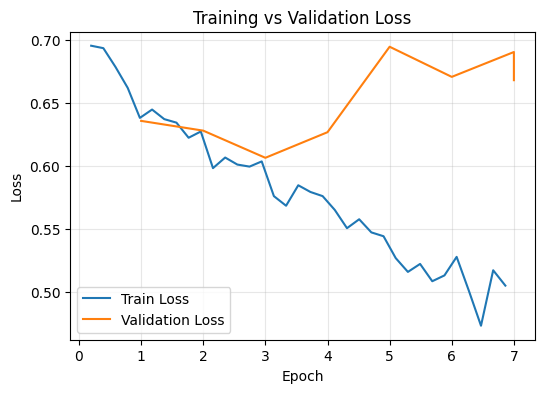

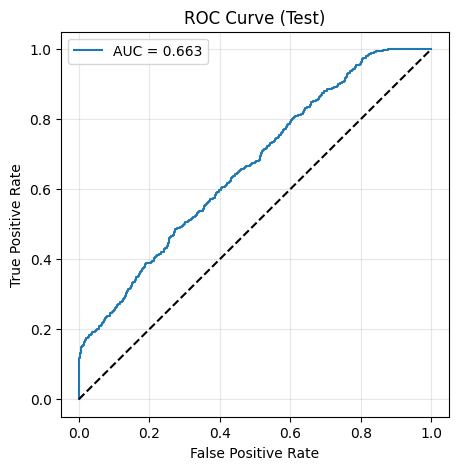

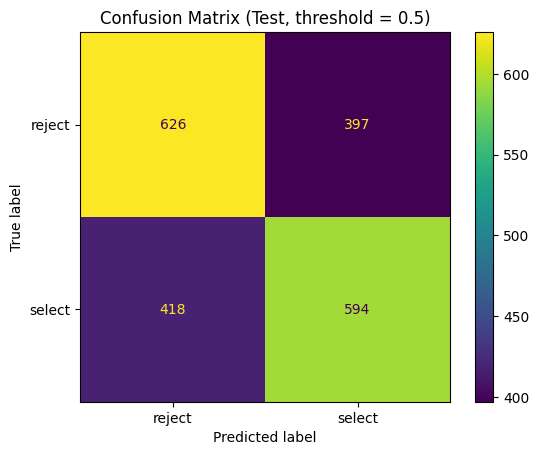

Best threshold (validation): 0.100
Best F1 (validation): 0.699

Classification Report (Test, calibrated threshold):
              precision    recall  f1-score   support

      reject       0.94      0.17      0.29      1023
      select       0.54      0.99      0.70      1012

    accuracy                           0.58      2035
   macro avg       0.74      0.58      0.49      2035
weighted avg       0.74      0.58      0.49      2035



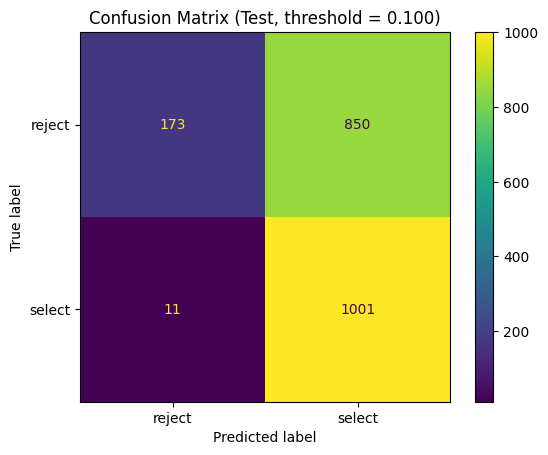

In [9]:
"""
Generate training/validation loss plots, ROC curve, confusion matrices,
and calibrate the classification threshold.
Plots are displayed inline in the notebook.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, auc,
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, classification_report
)

# Training vs Validation Loss

log_history = trainer.state.log_history

train_loss = [e["loss"] for e in log_history if "loss" in e]
epochs_t   = [e["epoch"] for e in log_history if "loss" in e]

val_loss = [e["eval_loss"] for e in log_history if "eval_loss" in e]
epochs_v = [e["epoch"] for e in log_history if "eval_loss" in e]

plt.figure(figsize=(6, 4))
plt.plot(epochs_t, train_loss, label="Train Loss")
plt.plot(epochs_v, val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# ROC Curve (Test)

preds = trainer.predict(ds_test_tok)

logits = preds.predictions
logits = logits - logits.max(axis=1, keepdims=True)

probs = np.exp(logits)
probs = probs / probs.sum(axis=1, keepdims=True)

y_true = preds.label_ids

fpr, tpr, _ = roc_curve(y_true, probs[:, 1])
roc_auc_val = auc(fpr, tpr)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_val:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Test)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Confusion Matrix (Test, threshold = 0.5)

y_pred = (probs[:, 1] >= 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["reject", "select"])

disp.plot(values_format="d")
plt.title("Confusion Matrix (Test, threshold = 0.5)")
plt.show()

# Threshold calibration using validation set (maximize F1)

preds_val = trainer.predict(ds_val_tok)

logits_v = preds_val.predictions
logits_v = logits_v - logits_v.max(axis=1, keepdims=True)

probs_v = np.exp(logits_v)
probs_v = probs_v / probs_v.sum(axis=1, keepdims=True)

y_val = preds_val.label_ids

precision, recall, thresholds = precision_recall_curve(y_val, probs_v[:, 1])
f1 = 2 * precision * recall / (precision + recall + 1e-12)

best_idx = f1.argmax()
best_thr = thresholds[best_idx]

print(f"Best threshold (validation): {best_thr:.3f}")
print(f"Best F1 (validation): {f1[best_idx]:.3f}")

# Confusion Matrix (Test, calibrated threshold)

y_pred_best = (probs[:, 1] >= best_thr).astype(int)

print("\nClassification Report (Test, calibrated threshold):")
print(classification_report(
    y_true,
    y_pred_best,
    target_names=["reject", "select"]
))

cm2 = confusion_matrix(y_true, y_pred_best)
disp = ConfusionMatrixDisplay(cm2, display_labels=["reject", "select"])

disp.plot(values_format="d")
plt.title(f"Confusion Matrix (Test, threshold = {best_thr:.3f})")
plt.show()
